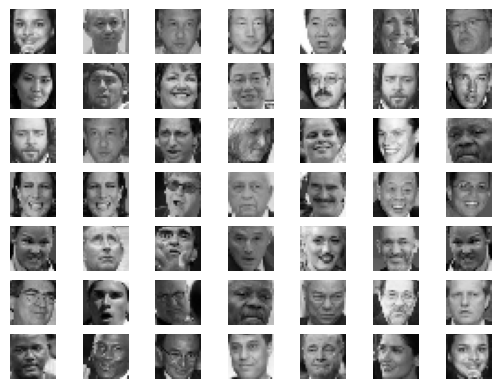

In [1]:
# example of loading and plotting the face dataset
import os
import numpy as np
import skimage
from matplotlib import pyplot

def load_data():
    path = os.path.join(os.path.dirname(skimage.__file__), 'data', 'lfw_subset.npy')
    all_imgs = np.load(path)                                   # (200, 25, 25) floats in [0, 1]
    faces = all_imgs[:100]                                     # first 100 are faces, last 100 are non-faces
    faces = np.concatenate([faces, faces[:, :, ::-1]])         # add mirrored copies (simple augmentation)
    imgs = (faces * 255.0).astype('uint8').reshape((-1, 25, 25, 1))
    rng = np.random.RandomState(0)
    idx = rng.permutation(len(imgs))
    imgs = imgs[idx]
    labels = np.zeros(len(imgs), dtype='int64')                # single class: "face"
    return (imgs[:180], labels[:180]), (imgs[180:], labels[180:])

# load the images into memory
(trainX, trainy), (testX, testy) = load_data()

# plot images from the training dataset
for i in range(49):
    # define subplot
    pyplot.subplot(7, 7, 1 + i)
    # turn off axis
    pyplot.axis('off')
    # plot raw pixel data
    pyplot.imshow(trainX[i, :, :, 0], cmap='gray', vmin=0, vmax=255)

pyplot.show()

In [2]:
print(trainX.shape)

(180, 25, 25, 1)


## Building blocks (NumPy, Keras-style)

In [3]:
# Dense layer
class Layer:
    trainable = True
    def params(self): return []

class Dense(Layer):
    def __init__(self, units, input_dim=None, activation=None):
        self.units, self.input_dim, self.activation = units, input_dim, activation
    def build(self, in_dim, rng):
        in_dim = int(np.prod(in_dim))
        self.W = rng.normal(0, np.sqrt(2.0 / in_dim), (in_dim, self.units)).astype('float32')
        self.b = np.zeros(self.units, dtype='float32')
        self.out_dim = self.units
    def params(self): return [self.W, self.b]
    def forward(self, x, training):
        self.x = x
        z = x @ self.W + self.b
        if self.activation == 'sigmoid':
            self.out = 1 / (1 + np.exp(-np.clip(z, -30, 30))); return self.out
        if self.activation == 'tanh':
            self.out = np.tanh(z); return self.out
        return z
    def backward(self, g):
        if self.activation == 'sigmoid': g = g * self.out * (1 - self.out)
        if self.activation == 'tanh': g = g * (1 - self.out ** 2)
        self.dW, self.db = self.x.T @ g, g.sum(0)
        return g @ self.W.T
    def grads(self): return [self.dW, self.db]

# quick check
d = Dense(10)
d.build(5, np.random.default_rng(0))
print('output shape:', d.forward(np.ones((4, 5), dtype='float32'), False).shape)

output shape: (4, 10)


In [4]:
# LeakyReLU and Dropout
class LeakyReLU(Layer):
    def __init__(self, alpha=0.2): self.alpha = alpha
    def build(self, in_dim, rng): self.out_dim = in_dim
    def forward(self, x, training):
        self.mask = x > 0
        return np.where(self.mask, x, self.alpha * x)
    def backward(self, g): return np.where(self.mask, g, self.alpha * g)

class Dropout(Layer):
    def __init__(self, rate): self.rate = rate
    def build(self, in_dim, rng): self.out_dim = in_dim; self.rng = rng
    def forward(self, x, training):
        if not training:
            self.m = 1.0; return x
        self.m = (self.rng.random(x.shape) >= self.rate) / (1 - self.rate)
        return x * self.m
    def backward(self, g): return g * self.m

# quick check
x = np.array([[-2.0, 3.0]])
print('leaky relu:', LeakyReLU(0.2).forward(x, False))
dr = Dropout(0.5); dr.build(2, np.random.default_rng(1))
print('dropout (training):', dr.forward(np.ones((1, 8)), True))
print('dropout (testing): ', dr.forward(np.ones((1, 8)), False))

leaky relu: [[-0.4  3. ]]
dropout (training): [[2. 2. 0. 2. 0. 0. 2. 0.]]
dropout (testing):  [[1. 1. 1. 1. 1. 1. 1. 1.]]


In [5]:
# Flatten and Reshape
class Flatten(Layer):
    def build(self, in_dim, rng): self.out_dim = int(np.prod(in_dim))
    def forward(self, x, training):
        self.shape = x.shape
        return x.reshape(len(x), -1)
    def backward(self, g): return g.reshape(self.shape)

class Reshape(Layer):
    def __init__(self, shape): self.shape = shape
    def build(self, in_dim, rng): self.out_dim = self.shape
    def forward(self, x, training): return x.reshape((len(x),) + self.shape)
    def backward(self, g): return g.reshape(len(g), -1)

# quick check
f = Flatten(); f.build((25, 25, 1), None)
print('flatten:', f.forward(np.zeros((3, 25, 25, 1)), False).shape)
r = Reshape((25, 25, 1))
print('reshape:', r.forward(np.zeros((3, 625)), False).shape)

flatten: (3, 625)
reshape: (3, 25, 25, 1)


In [6]:
# Adam optimizer
class Adam:
    def __init__(self, learning_rate=0.001, beta_1=0.9, beta_2=0.999, eps=1e-7):
        self.lr, self.b1, self.b2, self.eps = learning_rate, beta_1, beta_2, eps
        self.t, self.m, self.v = 0, {}, {}
    def step(self, params, grads):
        self.t += 1
        for p, g in zip(params, grads):
            k = id(p)
            m = self.m.setdefault(k, np.zeros_like(p))
            v = self.v.setdefault(k, np.zeros_like(p))
            m[:] = self.b1 * m + (1 - self.b1) * g
            v[:] = self.b2 * v + (1 - self.b2) * g * g
            mh = m / (1 - self.b1 ** self.t)
            vh = v / (1 - self.b2 ** self.t)
            p -= self.lr * mh / (np.sqrt(vh) + self.eps)

# quick check: minimise p^2, p should go towards 0
p = np.array([5.0])
opt = Adam(learning_rate=0.1)
for _ in range(200):
    opt.step([p], [2 * p])
print('p after 200 steps:', p)

p after 200 steps: [-0.00010954]


In [7]:
# Model base class: add layers, build, summary
class Model:
    _rng = np.random.default_rng(0)
    def __init__(self):
        self.layers, self.trainable, self.input_shape, self._built = [], True, None, False
    def add(self, layer):
        if not isinstance(layer, Model) and not self.layers and self.input_shape is None:
            if getattr(layer, 'input_dim', None): self.input_shape = (layer.input_dim,)
        self.layers.append(layer)
    def build(self, in_shape):
        self.input_shape, d = in_shape, in_shape
        for l in self.layers:
            if isinstance(l, Model): l.build(d)
            else: l.build(d, Model._rng)
            d = l.out_dim
        self.out_dim, self._built = d, True
    def _layers(self):
        for l in self.layers:
            if isinstance(l, Model): yield from l._layers()
            else: yield l
    def summary(self):
        if not self._built: self.build(self.input_shape)
        print('Model: "sequential"')
        print('-' * 60)
        print('%-26s %-20s %10s' % ('Layer (type)', 'Output Shape', 'Param #'))
        print('=' * 60)
        total = 0
        for l in self._layers():
            n = sum(p.size for p in l.params()); total += n
            od = l.out_dim if isinstance(l.out_dim, tuple) else (l.out_dim,)
            print('%-26s %-20s %10d' % (type(l).__name__.lower(), str((None,) + od), n))
        print('=' * 60)
        print('Total params:', total)

def plot_model(*a, **k): pass   # graphviz is not installed, summary() shows the architecture

# quick check
m = Model()
m.input_shape = (4,)
m.add(Dense(3)); m.add(LeakyReLU()); m.add(Dense(1, activation='sigmoid'))
m.build((4,))
m.summary()

Model: "sequential"
------------------------------------------------------------
Layer (type)               Output Shape            Param #
dense                      (None, 3)                    15
leakyrelu                  (None, 3)                     0
dense                      (None, 1)                     4
Total params: 19


In [8]:
# Sequential model: compile, predict, evaluate, train_on_batch
class Sequential(Model):
    def compile(self, loss, optimizer, metrics=None):
        self.loss, self.opt, self.metrics = loss, optimizer, metrics
    def forward(self, x, training):
        if not self._built:
            self.build(x.shape[1:] if x.ndim > 2 else (x.shape[1],))
        for l in self.layers: x = l.forward(x, training)
        return x
    def backward(self, g):
        for l in reversed(self.layers): g = l.backward(g)
        return g
    def predict(self, x, verbose=0): return self.forward(x, False)
    def _bce(self, p, y):
        p = np.clip(p, 1e-7, 1 - 1e-7)
        return float(np.mean(-(y * np.log(p) + (1 - y) * np.log(1 - p))))
    def evaluate(self, x, y, verbose=0):
        p = self.forward(x, False)
        return self._bce(p, y), float(np.mean((p > 0.5) == (y > 0.5)))
    def _is_trainable(self, l):
        for sub in self.layers:
            if isinstance(sub, Model) and l in list(sub._layers()): return sub.trainable
        return True
    def train_on_batch(self, x, y):
        p = self.forward(x, True)
        loss, acc = self._bce(p, y), float(np.mean((p > 0.5) == (y > 0.5)))
        pc = np.clip(p, 1e-7, 1 - 1e-7)
        g = (-(y / pc) + (1 - y) / (1 - pc)) / len(y)
        self.backward(g)
        dense = [l for l in self._layers() if isinstance(l, Dense) and self._is_trainable(l)]
        self.opt.step([p for l in dense for p in l.params()], [g for l in dense for g in l.grads()])
        return (loss, acc) if self.metrics else loss

# quick check: learn a tiny problem (label = 1 if x0 + x1 > 0)
rng = np.random.default_rng(3)
xt = rng.normal(size=(200, 2)).astype('float32')
yt = (xt.sum(1, keepdims=True) > 0).astype('float32')
t = Sequential()
t.add(Dense(8, input_dim=2)); t.add(LeakyReLU()); t.add(Dense(1, activation='sigmoid'))
t.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=0.01), metrics=['accuracy'])
print('before training:', t.evaluate(xt, yt))
for _ in range(300): t.train_on_batch(xt, yt)
print('after training: ', t.evaluate(xt, yt))

before training: (0.8050544857978821, 0.28)
after training:  (0.0321468785405159, 0.99)


## Discriminator

In [9]:
# example of defining the discriminator model
# define the standalone discriminator model
def define_discriminator(in_shape=(25,25,1)):
    model = Sequential()
    model.input_shape = in_shape

    model.add(Flatten())
    # hidden layers
    model.add(Dense(512));  model.add(LeakyReLU(alpha=0.2))
    model.add(Dense(256));  model.add(LeakyReLU(alpha=0.2))
    model.add(Dense(128));  model.add(LeakyReLU(alpha=0.2))

    # classifier
    model.add(Dropout(0.4))
    model.add(Dense(1, activation='sigmoid'))

    # compile model
    opt = Adam(learning_rate=0.0005, beta_1=0.5)
    model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
    model.build(in_shape)
    return model

In [10]:
# define model
model = define_discriminator()

# summarize the model
model.summary()

Model: "sequential"
------------------------------------------------------------
Layer (type)               Output Shape            Param #
flatten                    (None, 625)                   0
dense                      (None, 512)              320512
leakyrelu                  (None, 512)                   0
dense                      (None, 256)              131328
leakyrelu                  (None, 256)                   0
dense                      (None, 128)               32896
leakyrelu                  (None, 128)                   0
dropout                    (None, 128)                   0
dense                      (None, 1)                   129
Total params: 484865


## Load and scale the dataset

In [11]:
# Function to load the dataset and scale it
# load and prepare face training images
def load_real_samples():
    # load face dataset
    (trainX, _), (_, _) = load_data()
    # convert from unsigned ints to floats
    X = trainX.astype('float32')
    # scale from [0, 255] to [-1, 1]
    X = (X - 127.5) / 127.5
    return X

In [12]:
X = load_real_samples()
X[0]

array([[[-0.79607844],
        [-0.81960785],
        [-0.73333335],
        [-0.15294118],
        [ 0.21568628],
        [ 0.1764706 ],
        [ 0.27058825],
        [ 0.31764707],
        [ 0.35686275],
        [ 0.44313726],
        [ 0.4745098 ],
        [ 0.56078434],
        [ 0.49803922],
        [ 0.3882353 ],
        [ 0.27058825],
        [ 0.12156863],
        [ 0.01176471],
        [-0.2784314 ],
        [-0.5137255 ],
        [-0.8039216 ],
        [-0.85882354],
        [-0.75686276],
        [-0.8117647 ],
        [-0.7647059 ],
        [-0.7490196 ]],

       [[-0.85882354],
        [-0.827451  ],
        [-0.4745098 ],
        [ 0.3019608 ],
        [ 0.29411766],
        [ 0.21568628],
        [ 0.28627452],
        [ 0.40392157],
        [ 0.5058824 ],
        [ 0.5921569 ],
        [ 0.7019608 ],
        [ 0.7019608 ],
        [ 0.67058825],
        [ 0.54509807],
        [ 0.40392157],
        [ 0.21568628],
        [ 0.02745098],
        [-0.03529412],
        [

In [13]:
# select real samples; real label is 1
def generate_real_samples(dataset, n_samples):
    # choose random instances
    ix = np.random.randint(0, dataset.shape[0], n_samples)
    # retrieve selected images
    X = dataset[ix]
    # generate 'real' class labels (1)
    y = np.ones((n_samples, 1))
    return X, y

In [14]:
# generate n fake samples with class labels (random noise, used only to warm up the discriminator)
def generate_fake_samples(n_samples):
    # generate uniform random numbers in [0,1]
    X = np.random.rand(25 * 25 * 1 * n_samples)
    # update to have the range [-1, 1]
    X = -1 + X * 2
    # reshape into a batch of images
    X = X.reshape((n_samples, 25, 25, 1))
    # generate 'fake' class labels (0)
    y = np.zeros((n_samples, 1))
    return X, y

In [15]:
np.random.seed(1)
# train the discriminator model temporarily
def train_discriminator(model, dataset, n_iter=20, n_batch=32):
    half_batch = int(n_batch / 2)
    # manually enumerate epochs
    for i in range(n_iter):
        # get randomly selected 'real' samples
        X_real, y_real = generate_real_samples(dataset, half_batch)
        # update discriminator on real samples
        _, real_acc = model.train_on_batch(X_real, y_real)
        # generate 'fake' examples
        X_fake, y_fake = generate_fake_samples(half_batch)
        # update discriminator on fake samples
        _, fake_acc = model.train_on_batch(X_fake, y_fake)
        # summarize performance
        print('>%d real=%.0f%% fake=%.0f%%' % (i+1, real_acc*100, fake_acc*100))

# Example Training
model = define_discriminator()
dataset = load_real_samples()
train_discriminator(model, dataset)

>1 real=38% fake=25%
>2 real=94% fake=44%
>3 real=100% fake=94%
>4 real=94% fake=75%
>5 real=75% fake=94%
>6 real=94% fake=94%
>7 real=94% fake=100%
>8 real=94% fake=100%
>9 real=100% fake=100%
>10 real=94% fake=100%
>11 real=100% fake=100%
>12 real=88% fake=100%
>13 real=100% fake=100%
>14 real=100% fake=100%
>15 real=94% fake=100%
>16 real=94% fake=100%
>17 real=94% fake=100%
>18 real=100% fake=100%
>19 real=94% fake=100%
>20 real=100% fake=100%


## Generator

In [16]:
# define the standalone generator model
def define_generator(latent_dim):
    model = Sequential()
    model.input_shape = (latent_dim,)
    model.add(Dense(128, input_dim=latent_dim)); model.add(LeakyReLU(alpha=0.2))
    model.add(Dense(256));                       model.add(LeakyReLU(alpha=0.2))
    model.add(Dense(512));                       model.add(LeakyReLU(alpha=0.2))
    # output layer: 25x25x1 image in [-1, 1]
    model.add(Dense(625, activation='tanh'))
    model.add(Reshape((25, 25, 1)))
    model.build((latent_dim,))
    return model

# define size of latent space & model summary
latent_dim = 100
model = define_generator(latent_dim)
model.summary()

Model: "sequential"
------------------------------------------------------------
Layer (type)               Output Shape            Param #
dense                      (None, 128)               12928
leakyrelu                  (None, 128)                   0
dense                      (None, 256)               33024
leakyrelu                  (None, 256)                   0
dense                      (None, 512)              131584
leakyrelu                  (None, 512)                   0
dense                      (None, 625)              320625
reshape                    (None, 25, 25, 1)             0
Total params: 498161


In [17]:
# generate points in latent space as input for the generator
def generate_latent_points(latent_dim, n_samples):
    # generate points in the latent space
    x_input = np.random.randn(latent_dim * n_samples)
    # reshape into a batch of inputs for the network
    x_input = x_input.reshape(n_samples, latent_dim)
    return x_input

# use the generator to generate n fake examples, with class labels
def generate_fake_samples(g_model, latent_dim, n_samples):
    # generate points in latent space
    x_input = generate_latent_points(latent_dim, n_samples)
    # predict outputs
    X = g_model.predict(x_input)
    # create 'fake' class labels (0)
    y = np.zeros((n_samples, 1))
    return X, y

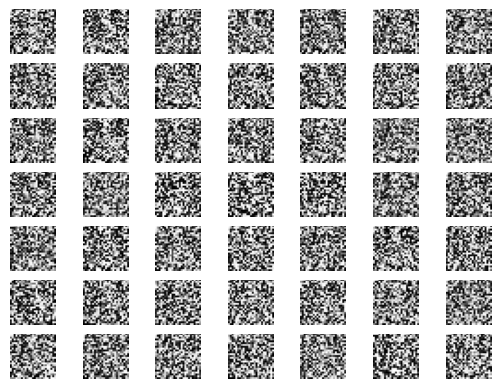

In [18]:
# size of the latent space
latent_dim = 100

# define the generator model
model = define_generator(latent_dim)

# generate samples (untrained generator -> noise)
n_samples = 49
X, _ = generate_fake_samples(model, latent_dim, n_samples)

# scale pixel values from [-1,1] to [0,1]
X = (X + 1) / 2.0

# plot the generated samples
for i in range(n_samples):
    # define subplot
    pyplot.subplot(7, 7, 1 + i)
    # turn off axis labels
    pyplot.axis('off')
    # plot single image
    pyplot.imshow(X[i, :, :, 0], cmap='gray')

# show the figure
pyplot.show()

## Combined GAN model

In [19]:
# define the combined generator and discriminator model, for updating the generator
def define_gan(g_model, d_model):
    # make weights in the discriminator not trainable
    d_model.trainable = False
    # connect them
    model = Sequential()
    # add generator
    model.add(g_model)
    # add the discriminator
    model.add(d_model)
    # compile model
    opt = Adam(learning_rate=0.0005, beta_1=0.5)
    model.compile(loss='binary_crossentropy', optimizer=opt)
    model.build(g_model.input_shape)
    return model

In [20]:
# create and save a plot of generated images
def save_plot(examples, epoch, n=7):
    # scale from [-1,1] to [0,1]
    examples = (examples + 1) / 2.0
    # plot images
    for i in range(n * n):
        # define subplot
        pyplot.subplot(n, n, 1 + i)
        # turn off axis
        pyplot.axis('off')
        # plot raw pixel data
        pyplot.imshow(examples[i, :, :, 0], cmap='gray')
    # save plot to file
    filename = 'generated_plot_e%03d.png' % (epoch+1)
    pyplot.savefig(filename)
    pyplot.close()

# evaluate the discriminator, plot generated images, save generator model
def summarize_performance(epoch, g_model, d_model, dataset, latent_dim, n_samples=150):
    # prepare real samples
    X_real, y_real = generate_real_samples(dataset, n_samples)
    # evaluate discriminator on real examples
    _, acc_real = d_model.evaluate(X_real, y_real, verbose=0)
    # prepare fake examples
    x_fake, y_fake = generate_fake_samples(g_model, latent_dim, n_samples)
    # evaluate discriminator on fake examples
    _, acc_fake = d_model.evaluate(x_fake, y_fake, verbose=0)
    # summarize discriminator performance
    print('>Accuracy real: %.0f%%, fake: %.0f%%' % (acc_real*100, acc_fake*100))
    # save plot
    save_plot(x_fake, epoch)
    # save the generator weights
    filename = 'generator_model_%03d.npz' % (epoch+1)
    np.savez(filename, *[p for l in g_model._layers() for p in l.params()])

## Train the GAN

In [21]:
from numpy import ones
np.random.seed(7)

# train the generator and discriminator
def train(g_model, d_model, gan_model, dataset, latent_dim, n_epochs=200, n_batch=32):
    bat_per_epo = int(dataset.shape[0] / n_batch)
    half_batch = int(n_batch / 2)
    # manually enumerate epochs
    for i in range(n_epochs):
        # enumerate batches over the training set
        for j in range(bat_per_epo):
            # get randomly selected 'real' samples
            X_real, y_real = generate_real_samples(dataset, half_batch)
            # update discriminator model weights
            d_loss1, _ = d_model.train_on_batch(X_real, y_real)
            # generate 'fake' examples
            X_fake, y_fake = generate_fake_samples(g_model, latent_dim, half_batch)
            # update discriminator model weights
            d_loss2, _ = d_model.train_on_batch(X_fake, y_fake)
            # prepare points in latent space as input for the generator
            X_gan = generate_latent_points(latent_dim, n_batch)
            # create inverted labels for the fake samples
            y_gan = ones((n_batch, 1))
            # update the generator via the discriminator's error
            g_loss = gan_model.train_on_batch(X_gan, y_gan)
            # summarize loss on this batch
            print('>%d, %d/%d, d1=%.3f, d2=%.3f g=%.3f' %
                  (i+1, j+1, bat_per_epo, d_loss1, d_loss2, g_loss))
        # evaluate the model performance, sometimes
        if (i+1) % 40 == 0:
            summarize_performance(i, g_model, d_model, dataset, latent_dim)

# size of the latent space
latent_dim = 100
# create the discriminator
d_model = define_discriminator()
# create the generator
g_model = define_generator(latent_dim)
# create the gan
gan_model = define_gan(g_model, d_model)
# load image data
dataset = load_real_samples()
# execute training
train(g_model, d_model, gan_model, dataset, latent_dim, n_epochs=200, n_batch=32)

>1, 1/5, d1=0.505, d2=1.493 g=0.959
>1, 2/5, d1=0.210, d2=0.745 g=1.844
>1, 3/5, d1=0.194, d2=0.536 g=2.354
>1, 4/5, d1=0.150, d2=0.454 g=2.774
>1, 5/5, d1=0.140, d2=0.307 g=2.294
>2, 1/5, d1=0.290, d2=0.429 g=2.294
>2, 2/5, d1=0.207, d2=0.475 g=2.977
>2, 3/5, d1=0.193, d2=0.258 g=2.668
>2, 4/5, d1=0.119, d2=0.345 g=2.793
>2, 5/5, d1=0.109, d2=0.310 g=2.881
>3, 1/5, d1=0.076, d2=0.258 g=3.229
>3, 2/5, d1=0.226, d2=0.204 g=3.017
>3, 3/5, d1=0.235, d2=0.481 g=3.453
>3, 4/5, d1=0.135, d2=0.173 g=4.476
>3, 5/5, d1=0.147, d2=0.240 g=3.898
>4, 1/5, d1=0.201, d2=0.296 g=4.736
>4, 2/5, d1=0.293, d2=0.252 g=5.462
>4, 3/5, d1=0.164, d2=0.053 g=3.948
>4, 4/5, d1=0.087, d2=1.117 g=5.615
>4, 5/5, d1=0.487, d2=0.032 g=5.030
>5, 1/5, d1=0.468, d2=0.799 g=6.083
>5, 2/5, d1=0.267, d2=0.086 g=5.121
>5, 3/5, d1=0.338, d2=0.253 g=4.492
>5, 4/5, d1=0.408, d2=0.918 g=5.770
>5, 5/5, d1=0.167, d2=0.022 g=5.869
>6, 1/5, d1=0.285, d2=0.189 g=4.191
>6, 2/5, d1=0.286, d2=1.419 g=6.980
>6, 3/5, d1=0.541, d2=0.018 

## Generated images during training

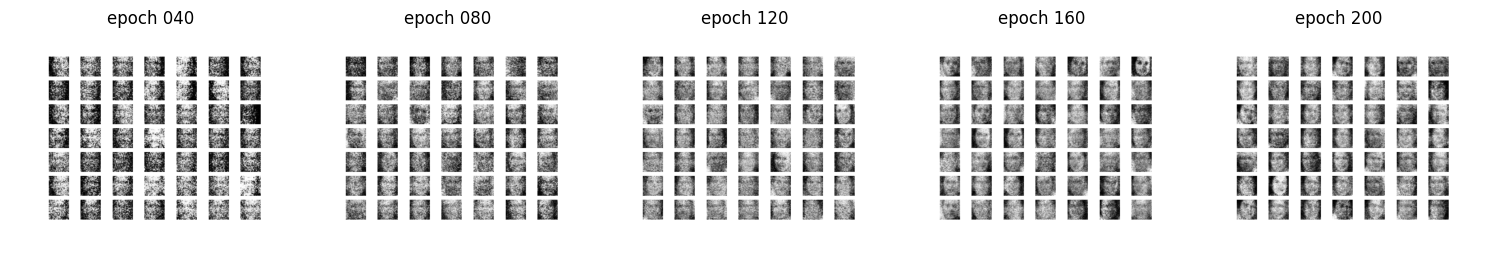

In [22]:
import matplotlib.image as mpimg
import glob
files = sorted(glob.glob('generated_plot_e*.png'))
fig, axes = pyplot.subplots(1, len(files), figsize=(3*len(files), 3.4))
for ax, f in zip(np.atleast_1d(axes), files):
    ax.imshow(mpimg.imread(f)); ax.axis('off'); ax.set_title('epoch ' + f[-7:-4])
pyplot.tight_layout(); pyplot.show()

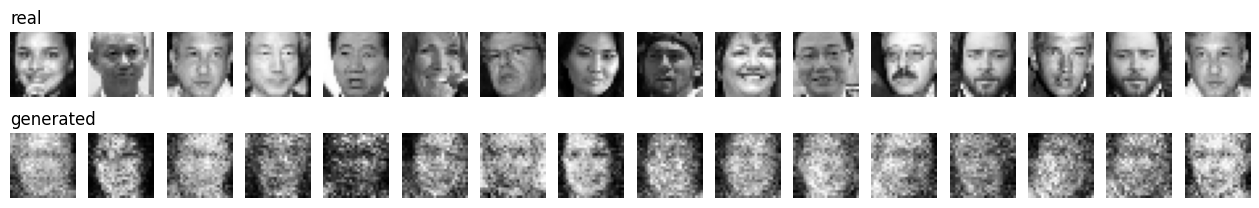

In [23]:
# final comparison: real faces vs. generated faces
X_gen, _ = generate_fake_samples(g_model, latent_dim, 16)
X_gen = (X_gen + 1) / 2.0
fig, axes = pyplot.subplots(2, 16, figsize=(16, 2.4))
for i in range(16):
    axes[0, i].imshow(trainX[i, :, :, 0], cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(X_gen[i, :, :, 0], cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_title('real', loc='left'); axes[1, 0].set_title('generated', loc='left')
pyplot.show()